# Part 2

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"


In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "C:\\Users\\weita\\Desktop\\MFE\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\Weitao_Su\\data\\data.db"


In [3]:
import sqlite3
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import scrapbook as sb

plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline


### 2.2

In [4]:
if not isinstance(ticker, str) or not ticker.strip():
    raise ValueError("Enter a ticker.")
ticker = ticker.strip().upper()
start = pd.Timestamp(start_date)
end = pd.Timestamp(end_date)
if pd.isna(start) or pd.isna(end) or start > end:
    raise ValueError("Enter valid dates with start_date <= end_date.")
start_date = start.strftime("%Y-%m-%d")
end_date = end.strftime("%Y-%m-%d")

db_file = Path(db_path).expanduser().resolve()
if not db_file.is_file():
    raise FileNotFoundError("Check db_path and run 01_data_cleaning.ipynb first.")

conn = sqlite3.connect(db_file.as_uri() + "?mode=ro", uri=True)
df = pd.read_sql_query(
    """
    SELECT ticker, ts, open, high, low, close, adj_close, volume
    FROM ohlc_hw_cleaned
    WHERE ticker = ? AND ts BETWEEN ? AND ?
    ORDER BY ts
    """,
    conn, params=(ticker, start_date, end_date), parse_dates=["ts"]
)
conn.close()

if df.empty:
    raise ValueError(f"No cleaned data for {ticker} from {start_date} to {end_date}.")
price_cols = ["open", "high", "low", "close", "adj_close"]
if (
    df.duplicated(["ticker", "ts"]).any()
    or not np.isfinite(df[price_cols]).all().all()
    or not df[price_cols].gt(0).all().all()
    or not df["open"].between(df["low"], df["high"]).all()
    or not df["close"].between(df["low"], df["high"]).all()
    or not (np.isfinite(df["volume"]) & df["volume"].ge(0)).all()
):
    raise ValueError("Cleaned data failed validation. Rerun Part 1.")

print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual coverage: {df['ts'].min().date()} to {df['ts'].max().date()}")
if len(df) < 21:
    print("20-day volatility is unavailable: 20 returns require at least 21 prices.")
if len(df) < 50:
    print("The 50-day moving average is unavailable: at least 50 prices are needed.")
if len(df) < 3:
    print("Volatility and Sharpe need at least two returns; unavailable values show N/A.")
display(df.head())
display(df.tail())


AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual coverage: 2024-06-03 to 2024-10-18


,ticker,ts,open,high,low,close,adj_close,volume
0,AAPL,2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
1,AAPL,2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2,AAPL,2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785
3,AAPL,2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753
4,AAPL,2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912


,ticker,ts,open,high,low,close,adj_close,volume
92,AAPL,2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
93,AAPL,2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
94,AAPL,2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
95,AAPL,2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
96,AAPL,2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


### 2.3

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from adjusted close."""
    return np.log(prices / prices.shift(1))

def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized sample volatility over a complete rolling window."""
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(252)

def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    peak = prices.cummax()
    return (prices - peak) / peak

def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe; return NaN for insufficient or constant returns."""
    out = returns.dropna()
    std = out.std(ddof=1)
    if len(out) < 2 or not np.isfinite(std) or np.isclose(std, 0, atol=1e-12):
        return np.nan
    return (out.mean() * 252 - risk_free_rate) / (std * np.sqrt(252))


In [6]:
df["daily_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["daily_return"])
df["drawdown"] = calculate_max_drawdown(df["adj_close"])
df["ma_50"] = df["adj_close"].rolling(50, min_periods=50).mean()
sharpe_ratio = calculate_sharpe_ratio(df["daily_return"])

display(df[["ts", "adj_close", "daily_return", "volatility", "drawdown", "ma_50"]].tail())


,ts,adj_close,daily_return,volatility,drawdown,ma_50
92,2024-10-14,231.30,0.016346,0.242503,-0.013856,223.6422
93,2024-10-15,233.85,0.010964,0.243942,-0.002984,224.1386
94,2024-10-16,231.78,-0.008891,0.241973,-0.011810,224.6344
95,2024-10-17,232.15,0.001595,0.206097,-0.010232,225.0858
96,2024-10-18,235.00,0.012202,0.209521,0.000000,225.5246


### 2.4

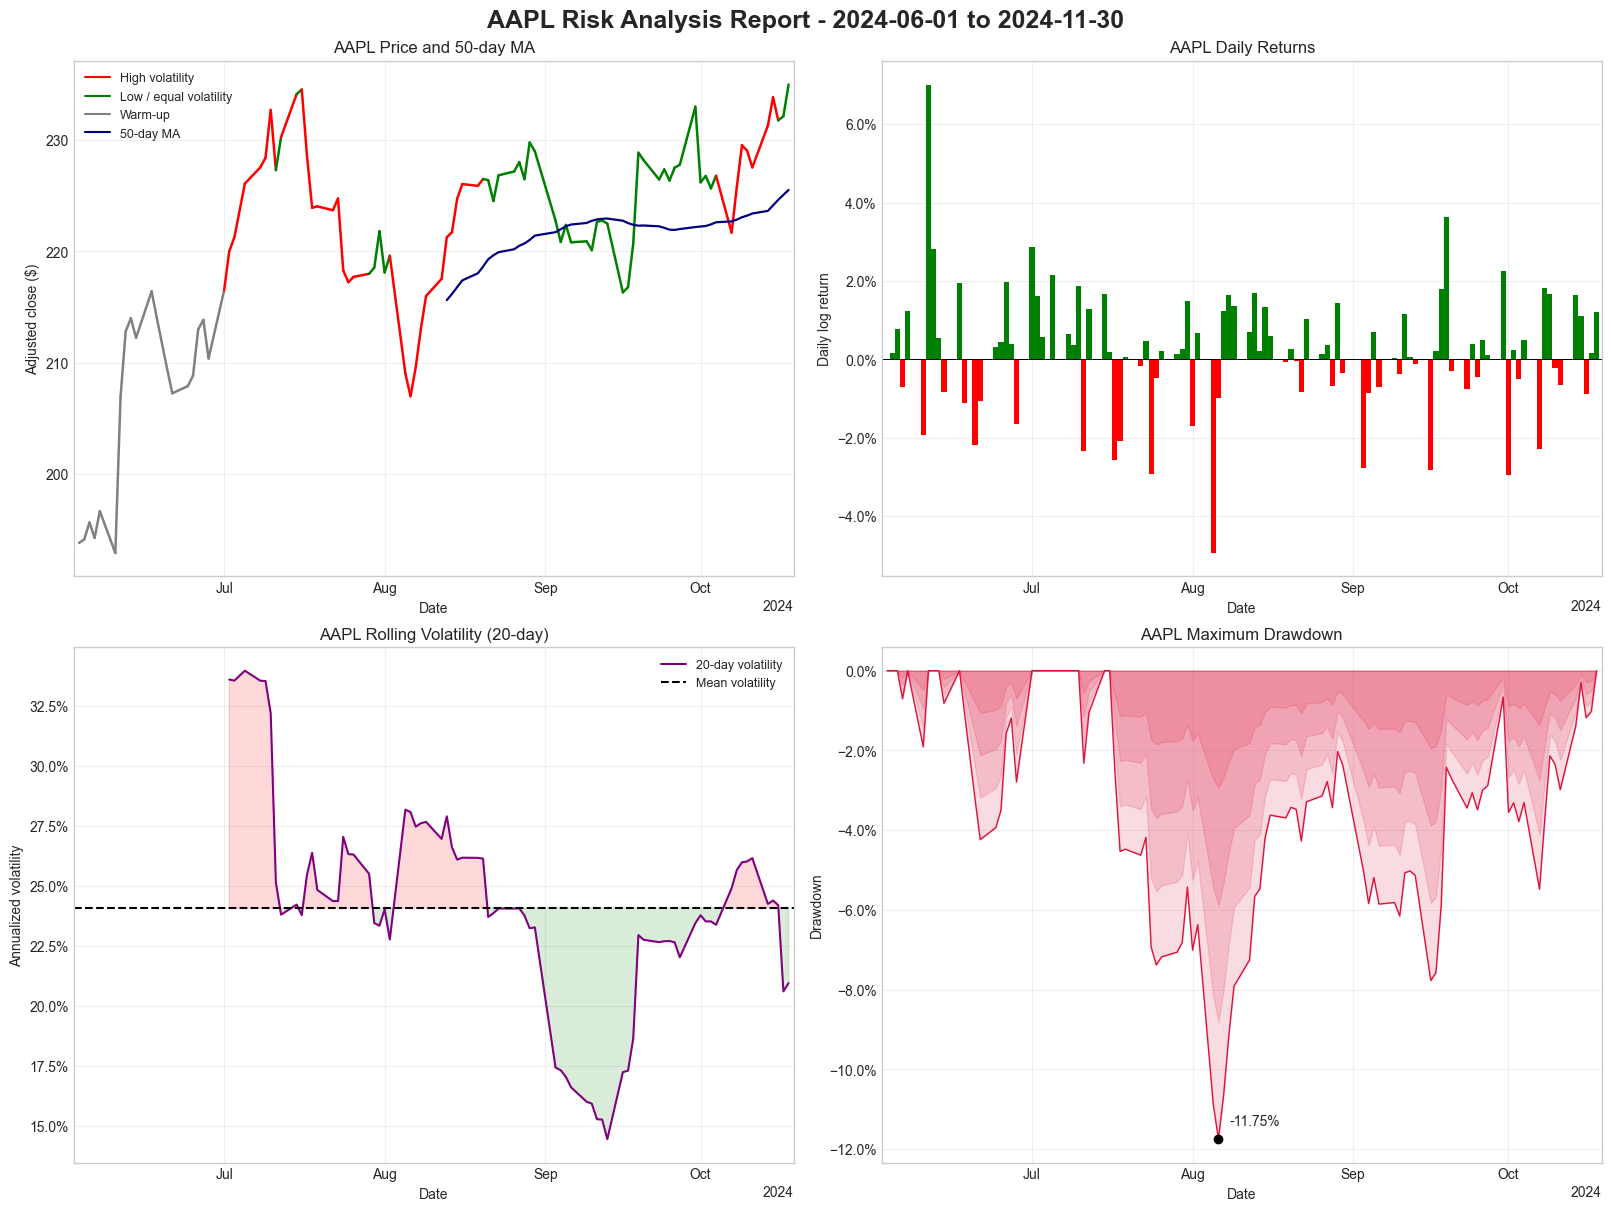

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(
    f"{ticker} Risk Analysis Report - {start_date} to {end_date}",
    fontsize=18, fontweight="bold"
)
mean_volatility = df["volatility"].mean()

for i in range(1, len(df)):
    vol = df["volatility"].iloc[i]
    color = "gray" if pd.isna(vol) else "red" if vol > mean_volatility else "green"
    axes[0, 0].plot(
        df["ts"].iloc[i-1:i+1], df["adj_close"].iloc[i-1:i+1],
        color=color, linewidth=1.8
    )
if len(df) == 1:
    axes[0, 0].scatter(df["ts"], df["adj_close"], color="gray")
axes[0, 0].plot(df["ts"], df["ma_50"], color="navy", linewidth=1.6)
axes[0, 0].legend(handles=[
    Line2D([0], [0], color="red", label="High volatility"),
    Line2D([0], [0], color="green", label="Low / equal volatility"),
    Line2D([0], [0], color="gray", label="Warm-up"),
    Line2D([0], [0], color="navy", label="50-day MA"),
], fontsize=9, loc="upper left")
axes[0, 0].set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")

axes[0, 1].bar(
    df["ts"], df["daily_return"], width=1,
    color=np.where(df["daily_return"].ge(0), "green", "red")
)
axes[0, 1].axhline(0, color="black", linewidth=0.7)
axes[0, 1].set(title=f"{ticker} Daily Returns", ylabel="Daily log return")
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(1))

axes[1, 0].plot(df["ts"], df["volatility"], color="purple", label="20-day volatility")
if pd.notna(mean_volatility):
    axes[1, 0].axhline(
        mean_volatility, color="black", linestyle="--", label="Mean volatility"
    )
    axes[1, 0].fill_between(
        df["ts"], df["volatility"], mean_volatility,
        where=df["volatility"].gt(mean_volatility),
        color="red", alpha=0.15, interpolate=True
    )
    axes[1, 0].fill_between(
        df["ts"], df["volatility"], mean_volatility,
        where=df["volatility"].lt(mean_volatility),
        color="green", alpha=0.15, interpolate=True
    )
else:
    axes[1, 0].text(
        0.5, 0.5, "20-day volatility unavailable",
        ha="center", transform=axes[1, 0].transAxes
    )
axes[1, 0].set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility")
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 0].legend(fontsize=9)

for fraction in [1.0, 0.75, 0.5, 0.25]:
    axes[1, 1].fill_between(
        df["ts"], df["drawdown"] * fraction, 0, color="crimson", alpha=0.15
    )
axes[1, 1].plot(df["ts"], df["drawdown"], color="crimson", linewidth=1)
worst = df["drawdown"].idxmin()
axes[1, 1].scatter(df.loc[worst, "ts"], df.loc[worst, "drawdown"], color="black", zorder=3)
axes[1, 1].annotate(
    f'{df.loc[worst, "drawdown"]:.2%}',
    (df.loc[worst, "ts"], df.loc[worst, "drawdown"]),
    xytext=(8, 10), textcoords="offset points"
)
axes[1, 1].set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown")
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))

for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.set_xlim(df["ts"].min() - pd.Timedelta(days=1), df["ts"].max() + pd.Timedelta(days=1))
    ax.grid(True, alpha=0.3)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.show()


### 2.5

In [8]:
returns = df["daily_return"].dropna()
n = len(returns)
total_return = df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1
annualized_return = np.expm1(returns.sum() * 252 / n) if n else np.nan
annualized_volatility = returns.std(ddof=1) * np.sqrt(252) if n >= 2 else np.nan

summary = pd.Series({
    "Total Return": total_return,
    "Annualized Return": annualized_return,
    "Annualized Volatility": annualized_volatility,
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": df["drawdown"].min(),
    "Best Day": returns.max(),
    "Worst Day": returns.min(),
    "Positive Days": returns.gt(0).mean(),
    "Average Up Day": returns.loc[returns.gt(0)].mean(),
    "Average Down Day": returns.loc[returns.lt(0)].mean(),
}, name="Value")

rows = []
signed_metrics = ["Total Return", "Annualized Return", "Best Day",
                  "Worst Day", "Average Up Day", "Average Down Day"]
for metric, value in summary.items():
    if pd.isna(value):
        formatted = "N/A"
    elif metric == "Sharpe Ratio":
        formatted = f"{value:.2f}"
    elif metric in signed_metrics:
        formatted = f"{value:+.2%}"
    else:
        formatted = f"{value:.2%}"
    rows.append({"Metric": metric, "Value": formatted})

summary_table = pd.DataFrame(rows)
display(summary_table)


,Metric,Value
0,Total Return,+21.25%
1,Annualized Return,+65.84%
2,Annualized Volatility,25.45%
3,Sharpe Ratio,1.91
4,Maximum Drawdown,-11.75%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,62.50%
8,Average Up Day,+1.09%
9,Average Down Day,-1.28%


In [9]:
stats = {
    "ticker": ticker,
    "avg_daily_return": returns.mean(),
    "avg_volatility": df["volatility"].mean(),
    "max_drawdown": df["drawdown"].min(),
    "sharpe_ratio": sharpe_ratio,
    "total_return": total_return,
    "start_date": start_date,
    "end_date": end_date,
    "actual_start_date": df["ts"].min().strftime("%Y-%m-%d"),
    "actual_end_date": df["ts"].max().strftime("%Y-%m-%d"),
    "trading_days": len(df),
}
sb.glue("stats", {name: None if pd.isna(value) else value for name, value in stats.items()})
